# Linear Regression Lab (SciKit-Learn) — Salary Dataset
## Student Notebook (Fill in the Blanks)

This notebook is available in the codebase that comes along with the book. In this exercise, you will learn how to implement Linear Regression using Scikit-learn, how to build a Machine Learning regression model, and how to draw relevant plots.

**Dataset:** Salary dataset from the codebase (example: `Salary_Data.csv`).

Follow the step-by-step instructions and complete each cell.

## Step 1 — Import Required Libraries
**Task:** Complete the imports.

In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix,mean_absolute_error,mean_squared_error,r2_score

## Step 2 — Load the Salary Dataset
**Task:** Read the CSV file from the codebase and display top rows.

In [30]:
df = pd.read_csv("Salary_Data.csv")   # e.g., "Salary_Data.csv"
df.head()

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


## Step 3 — Explore the Dataset
**Task:** Print shape, columns, missing values, and statistics.

In [31]:
print("Shape:", df.shape)

print("\nColumns:", df.columns.tolist())

print("\nMissing values:\n", df.isnull().sum())

df.describe()

Shape: (30, 2)

Columns: ['YearsExperience', 'Salary']

Missing values:
 YearsExperience    0
Salary             0
dtype: int64


,YearsExperience,Salary
count,30.000000,30.000000
mean,5.313333,76003.000000
std,2.837888,27414.429785
min,1.100000,37731.000000
25%,3.200000,56720.750000
50%,4.700000,65237.000000
75%,7.700000,100544.750000
max,10.500000,122391.000000


## Step 4 — Define Features (X) and Target (y)
**Task:** Use `YearsExperience` as X and `Salary` as y. Remember: X must be 2D.

In [32]:
X = df[[ "YearsExperience"]]     # YearsExperience
y = df["Salary"]           # Salary

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (30, 1)
y shape: (30,)


## Step 5 — Split Dataset into Training and Test Sets
**Task:** Use `train_test_split` with a test size and random state.

In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=1
)

print("X_train:", X_train.shape, "X_test:", X_test.shape)

X_train: (24, 1) X_test: (6, 1)


## Step 6 — Train the Linear Regression Model
**Task:** Create and fit the model. Print intercept and coefficient.

In [34]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])

Intercept: 25609.89799835482
Coefficient: 9332.94473799272


## Step 7 — Make Predictions
**Task:** Predict salary for the test set and display first 5 rows of results.

In [35]:
y_pred = model.predict(X_test)

df =pd.DataFrame({
    "YearsExperience": X_test["YearsExperience"].values,
    "ActualSalary": y_test.values,
    "PredictedSalary": y_pred
}).head()

## Step 8 — Evaluate the Model
**Task:** Compute MAE, MSE, RMSE, and R².

In [55]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R^2 :", r2)

MAE : 6185.994575326634
MSE : 51338023.49224842
RMSE: 7165.055721503387
R^2 : 0.7616681465472094


# Visualization Section

## Step 9 — Scatter Plot of Actual Data
**Task:** Create a scatter plot of YearsExperience vs Salary.

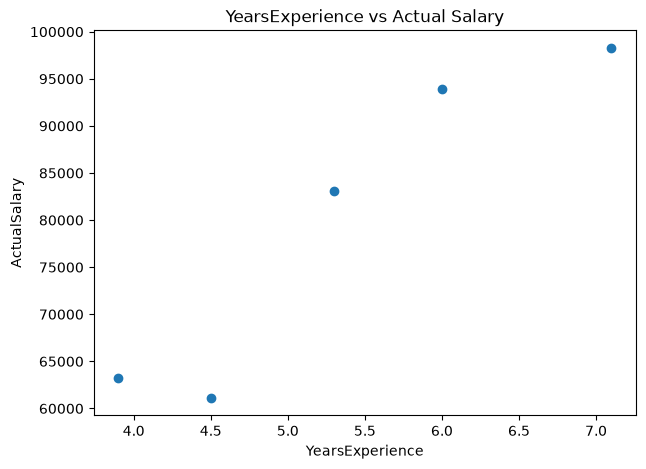

In [56]:
plt.figure(figsize=(7, 5))
plt.scatter(df["YearsExperience"], df["ActualSalary"])
plt.title("YearsExperience vs Actual Salary")
plt.xlabel("YearsExperience")
plt.ylabel("ActualSalary")
plt.show()

## Step 10 — Plot Regression Line (Train Set)
**Task:** Plot training points and regression line.

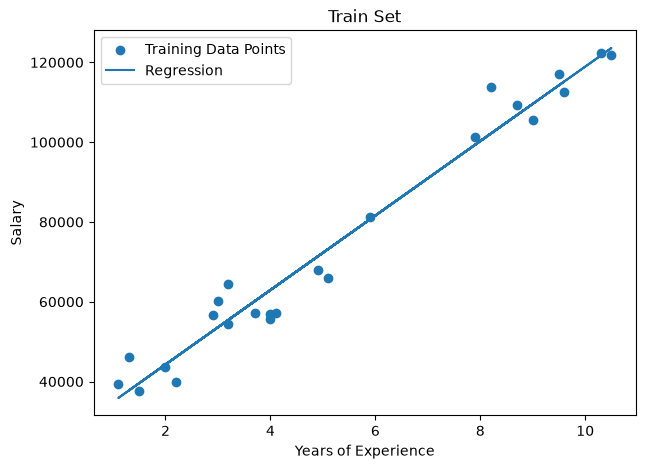

In [69]:
plt.figure(figsize=(7, 5))
plt.scatter(X_train["YearsExperience"], y_train, label="Training Data Points")

y_train_line = model.predict(X_train)
plt.plot(X_train["YearsExperience"], y_train_line, label="Regression")

plt.title("Train Set")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.legend()
plt.show()

## Step 11 — Plot Regression Line (Test Set)
**Task:** Plot test points and regression line (sorted X for a clean line).

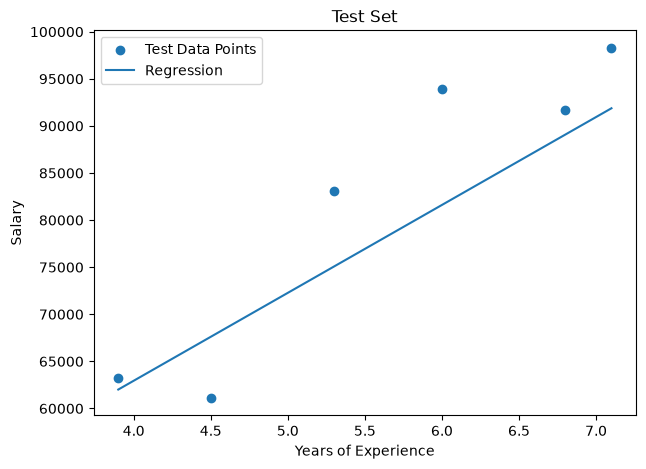

In [74]:
plt.figure(figsize=(7, 5))
plt.scatter(X_test["YearsExperience"], y_test, label="Test Data Points")

X_line = X_test.sort_values(by="YearsExperience")
y_line = model.predict(X_line)

plt.plot(X_line["YearsExperience"], y_line, label="Regression")

plt.title("Test Set")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.legend()
plt.show()

## Step 12 — Residual Plot (Optional)
**Task:** Compute residuals and plot residuals vs predicted values.

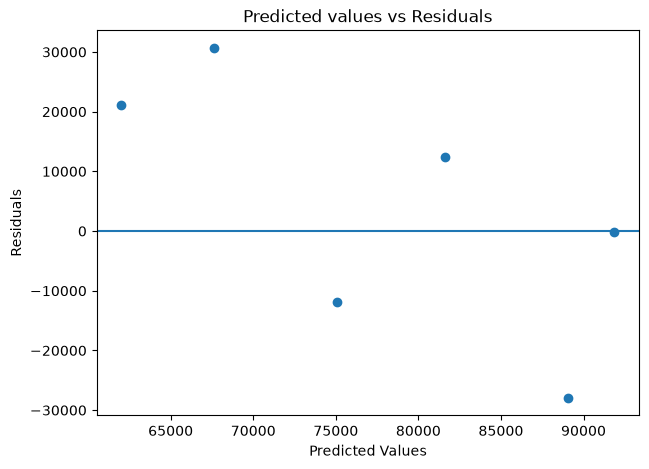

In [86]:
residuals = y_test - y_line

plt.figure(figsize=(7, 5))
plt.scatter(y_line,residuals)
plt.axhline(0)
plt.title("Predicted values vs Residuals")
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.show()

# Mini Exercises (Write Your Answers)
**Exercise A:** What does the slope represent in this dataset?

**Exercise B:** If the model has a high R², what does it indicate?

**Exercise C:** How can outliers affect the regression line?


In [ ]:
# Exercise A:
# Slope represents the change in salary with change in YOE. If the salary increases with YOE it has a positive slope. 
# If salary descreases with YOE it has a negative slope

# Exercise B:
# High R2 means the model does a good job of explaining the change in the depenedent variable with change in the independent vaiable

# Exercise C:
# Outliers can cause changes in the slope and R2 and introduce noise into the model by reducing accuracy

# Extension Challenge (Optional)
1. Change the test size (example: 0.2 → 0.3)
2. Retrain the model and compare evaluation metrics
3. Write your conclusion in 2–3 lines


In [ ]:
# YOUR CODE HERE
# The ceofficient and intercept both increased when the test size was oncreased to 0.3. This means that the salary with 0 YOE is higher when considering a 
# test size of 0.3 The residuals also had a max of 40,000 instead of 30,000 and a minmum of -60,000 instead of -30,000. With 0.3 test size the R2 was better suggesting that
# it is a better option for the model